In [47]:
import pandas as pd
import matplotlib.pyplot as plt

In [48]:
#read the cvs file 
df = pd.read_csv('EPL.csv')
df.head()

,timestamp,date_GMT,status,attendance,home_team_name,away_team_name,referee,Game Week,Pre-Match PPG (Home),Pre-Match PPG (Away),...,odds_ft_home_team_win,odds_ft_draw,odds_ft_away_team_win,odds_ft_over15,odds_ft_over25,odds_ft_over35,odds_ft_over45,odds_btts_yes,odds_btts_no,stadium_name
0,1533927600,Aug 10 2018 - 7:00pm,complete,74439,Manchester United,Leicester City,Andre Marriner,1,0.0,0.0,...,1.37,4.98,9.81,1.33,2.00,3.60,7.50,2.05,1.69,Old Trafford (Manchester)
1,1533987000,Aug 11 2018 - 11:30am,complete,51749,Newcastle United,Tottenham Hotspur,Martin Atkinson,1,0.0,0.0,...,4.51,3.77,1.84,1.31,1.95,3.50,5.75,1.83,1.87,St. James' Park (Newcastle upon Tyne)
2,1533996000,Aug 11 2018 - 2:00pm,complete,10353,AFC Bournemouth,Cardiff City,Kevin Friend,1,0.0,0.0,...,2.03,3.51,3.96,1.31,1.95,3.45,6.70,1.83,1.83,Vitality Stadium (Bournemouth- Dorset)
3,1533996000,Aug 11 2018 - 2:00pm,complete,24821,Fulham,Crystal Palace,Mike Dean,1,0.0,0.0,...,2.31,3.44,3.26,1.28,1.87,3.20,7.00,1.71,2.00,Craven Cottage (London)
4,1533996000,Aug 11 2018 - 2:00pm,complete,24121,Huddersfield Town,Chelsea,Chris Kavanagh,1,0.0,0.0,...,7.47,4.27,1.51,1.29,1.91,3.30,6.95,2.00,1.71,John Smith's Stadium (Huddersfield- West Yorks...


In [49]:
df1 = df[["date_GMT", 
          "home_team_name", 
          "away_team_name", 
          "home_team_goal_count", 
          "away_team_goal_count"]].head()
df1

,date_GMT,home_team_name,away_team_name,home_team_goal_count,away_team_goal_count
0,Aug 10 2018 - 7:00pm,Manchester United,Leicester City,2,1
1,Aug 11 2018 - 11:30am,Newcastle United,Tottenham Hotspur,1,2
2,Aug 11 2018 - 2:00pm,AFC Bournemouth,Cardiff City,2,0
3,Aug 11 2018 - 2:00pm,Fulham,Crystal Palace,0,2
4,Aug 11 2018 - 2:00pm,Huddersfield Town,Chelsea,0,3


In [50]:
#check for missing values in each column
df.isnull().sum().sort_values(ascending=False).head(15)

#Check for duplicate rows 
print("Duplicate rows:", df.duplicated().sum())

# Check data types
print(df.dtypes)

Duplicate rows: 0
timestamp           int64
date_GMT           object
status             object
attendance          int64
home_team_name     object
                   ...   
odds_ft_over35    float64
odds_ft_over45    float64
odds_btts_yes     float64
odds_btts_no      float64
stadium_name       object
Length: 66, dtype: object


In [51]:
# Create a new column to store the match result
df["match_result"] = "Draw"

#Home team wins
df.loc[
    df["home_team_goal_count"] > df ["away_team_goal_count"],
    "match_result"] = "Home Win"

#Away team win
df.loc[
    df["home_team_goal_count"] < df ["away_team_goal_count"],
    "match_result"] = "Away Win"

#count each value
print(df["match_result"].value_counts())

match_result
Home Win    181
Away Win    128
Draw         71
Name: count, dtype: int64


In [52]:
#Calculating the percentages
result_counts = df["match_result"].value_counts()

result_percentages = (df["match_result"].value_counts(normalize=True) * 100).round(2)

result_percentages

match_result
Home Win    47.63
Away Win    33.68
Draw        18.68
Name: proportion, dtype: float64

### Visualization of Outcomes

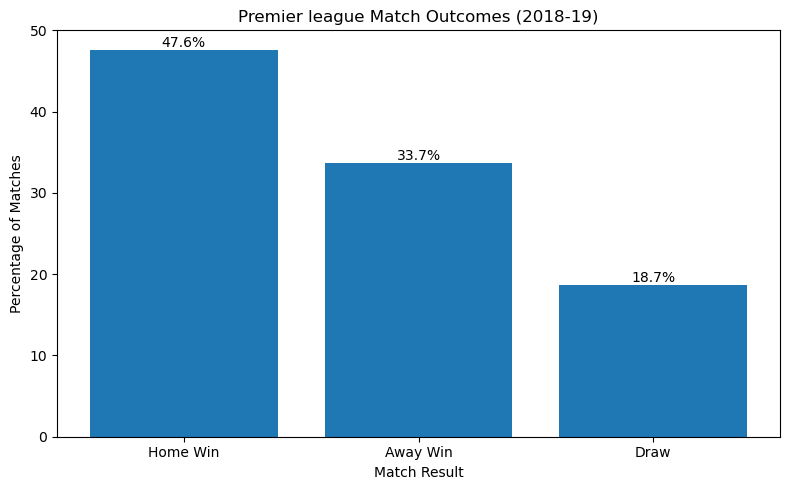

In [54]:
plt.figure(figsize=(8, 5)) #sets the chart dimentions

bars = plt.bar(
    result_percentages.index,
    result_percentages.values) #createsa bar chart

#Add percentages above each bar
for bar in bars:
    
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.1f}%",
        ha="center",
        va="bottom") 



plt.title("Premier league Match Outcomes (2018-19)")
plt.xlabel("Match Result")
plt.ylabel("Percentage of Matches")
plt.tight_layout() #improves spacing

plt.show() #displays the chart



### Which team will score more goals 

In [55]:
#Calculate total goals score by each home team

home_goals = df.groupby("home_team_name")["home_team_goal_count"].sum()

#Calculate total goals score by each away team

away_goals = df.groupby("away_team_name")["away_team_goal_count"].sum()

#Combine the two totals for each team
total_goals = home_goals.add(away_goals, fill_value = 0)

#Display the 10 highest-scoring teams
top_10_scores = total_goals.sort_values(ascending = False).head(10)
top_10_scores

home_team_name
Manchester City      95
Liverpool            89
Arsenal              73
Tottenham Hotspur    67
Manchester United    65
Chelsea              63
AFC Bournemouth      56
Everton              54
West Ham United      52
Watford              52
dtype: int64

### Horizontal team goals ranking bar chart

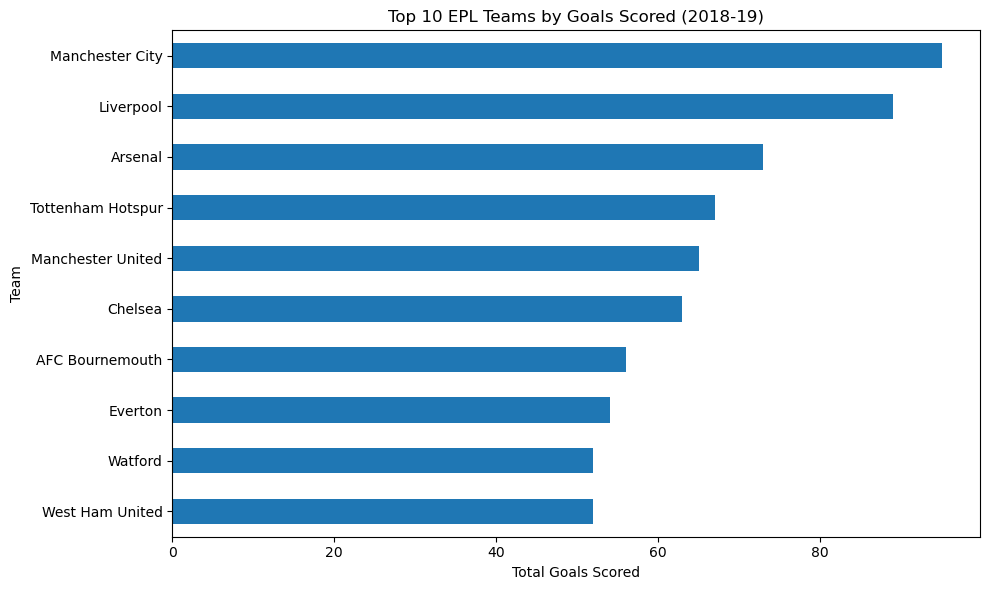

In [56]:
plt.figure(figsize=(10,6))

top_10_scores.sort_values().plot(kind="barh")

plt.title("Top 10 EPL Teams by Goals Scored (2018-19)")
plt.xlabel("Total Goals Scored")
plt.ylabel("Team")

plt.tight_layout()
plt.show()

### Goals per match 

In [10]:
home_matches = df.groupby("home_team_name").size()
away_matches = df.groupby("away_team_name").size()

matches_played = home_matches.add(away_matches, fill_value=0)

goals_per_match = total_goals / matches_played

top10_avg = goals_per_match.sort_values(ascending=False).head(10)
top10_avg

home_team_name
Manchester City      2.500000
Liverpool            2.342105
Arsenal              1.921053
Tottenham Hotspur    1.763158
Manchester United    1.710526
Chelsea              1.657895
AFC Bournemouth      1.473684
Everton              1.421053
West Ham United      1.368421
Watford              1.368421
dtype: float64

### Home and Away win rate 

In [11]:
# Calculate home wins for each team
home_wins = df[
    df["home_team_goal_count"] > df["away_team_goal_count"]
    ].groupby("home_team_name").size()

# Calculate away wins for each team
away_wins = df[
    df["home_team_goal_count"] < df["away_team_goal_count"]
    ].groupby("away_team_name").size()

# Calculates home and away matches played
home_matches = df.groupby("home_team_name").size()
away_matches = df.groupby("away_team_name").size()

# Calculates win pecentages
home_win_rate = (home_wins / home_matches) *100
away_win_rate = (away_wins / away_matches) *100

#Combine into one table 

win_rates = pd.DataFrame({
    "Home Win Rate": home_win_rate,
    "Away Win Rate": away_win_rate })

win_rates.round(2).head()



,Home Win Rate,Away Win Rate
AFC Bournemouth,42.11,26.32
Arsenal,73.68,36.84
Brighton & Hove Albion,31.58,15.79
Burnley,36.84,21.05
Cardiff City,31.58,21.05


In [13]:
#Calculate the difference 
win_rates = win_rates.drop(columns=["Home Advantage"], errors="ignore")

win_rates["Home Advantage"] = (win_rates["Home Win Rate"] - win_rates["Away Win Rate"])

win_rates.sort_values("Home Advantage", ascending=False).round(2).head(10)

,Home Win Rate,Away Win Rate,Home Advantage
Arsenal,73.68,36.84,36.84
Everton,52.63,26.32,26.32
Fulham,31.58,5.26,26.32
Manchester City,94.74,73.68,21.05
Liverpool,89.47,68.42,21.05
Wolverhampton Wanderers,52.63,31.58,21.05
Newcastle United,42.11,21.05,21.05
Chelsea,63.16,47.37,15.79
Brighton & Hove Albion,31.58,15.79,15.79
West Ham United,47.37,31.58,15.79


Visualization

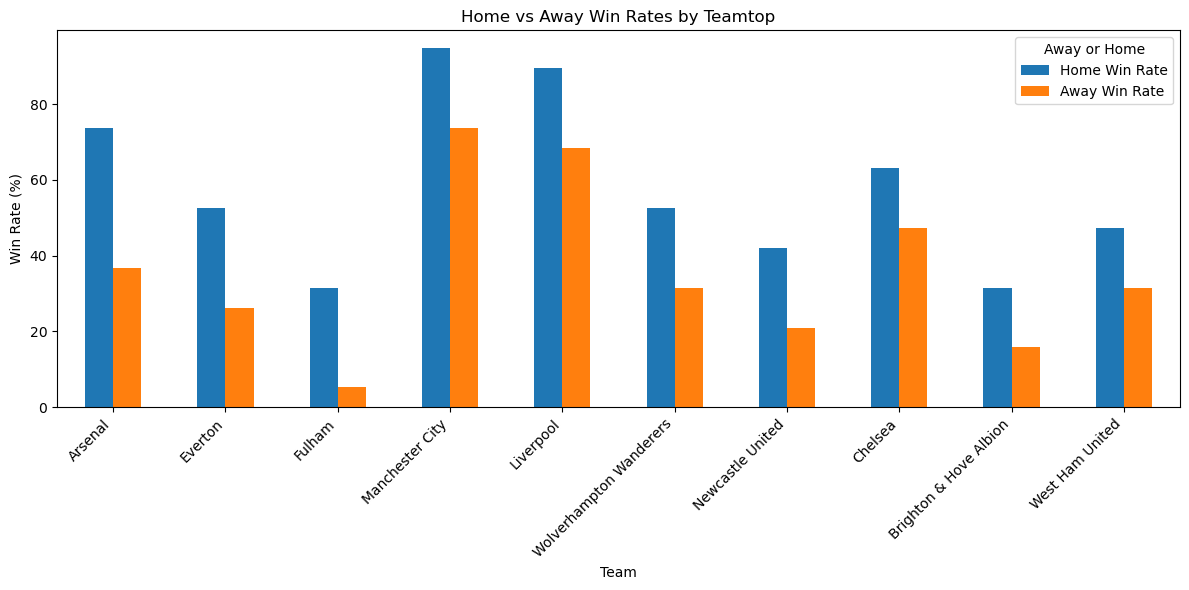

In [57]:
top_home_advantage = win_rates.sort_values("Home Advantage", ascending=False).round(2).head(10)

top_home_advantage[["Home Win Rate", "Away Win Rate"]].plot(kind="bar", figsize=(12, 6))

plt.title("Home vs Away Win Rates")
plt.xlabel("Team")
plt.ylabel("Win Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Away or Home")
plt.tight_layout()
plt.show()
    

### Shots on target vs goals

In [16]:
print([col for col in df.columns 
       if "shot" in col.lower()
       or "goal" in col.lower()])

['home_team_goal_count', 'away_team_goal_count', 'total_goal_count', 'total_goals_at_half_time', 'home_team_goal_count_half_time', 'away_team_goal_count_half_time', 'home_team_goal_timings', 'away_team_goal_timings', 'home_team_shots', 'away_team_shots', 'home_team_shots_on_target', 'away_team_shots_on_target', 'home_team_shots_off_target', 'away_team_shots_off_target', 'average_goals_per_match_pre_match']


In [28]:
print(df.isnull().sum()[
    [col for col in df.columns 
       if "shot" in col.lower()
       or "goal" in col.lower()]])

home_team_goal_count                   0
away_team_goal_count                   0
total_goal_count                       0
total_goals_at_half_time               0
home_team_goal_count_half_time         0
away_team_goal_count_half_time         0
home_team_goal_timings                88
away_team_goal_timings               119
home_team_shots                        0
away_team_shots                        0
home_team_shots_on_target              0
away_team_shots_on_target              0
home_team_shots_off_target             0
away_team_shots_off_target             0
average_goals_per_match_pre_match      0
dtype: int64


In [30]:
##Creating team level match dataset
#Home team statistics
home_stats = df[[ "home_team_name", "home_team_goal_count", "home_team_shots_on_target"]].copy()
home_stats.columns = ["team", "goals", "shots_on_target"]

#Away team statistics
away_stats = df[[ "away_team_name", "away_team_goal_count", "away_team_shots_on_target"]].copy()
away_stats.columns = ["team", "goals", "shots_on_target"]

#Combine home and away stats
team_match_stats = pd.concat([home_stats, away_stats], ignore_index=True)
team_match_stats

,team,goals,shots_on_target
0,Manchester United,2,6
1,Newcastle United,1,2
2,AFC Bournemouth,2,4
3,Fulham,0,6
4,Huddersfield Town,0,1
...,...,...,...
755,Wolverhampton Wanderers,0,2
756,Cardiff City,2,4
757,Huddersfield Town,1,3
758,Everton,2,9


### Visualization

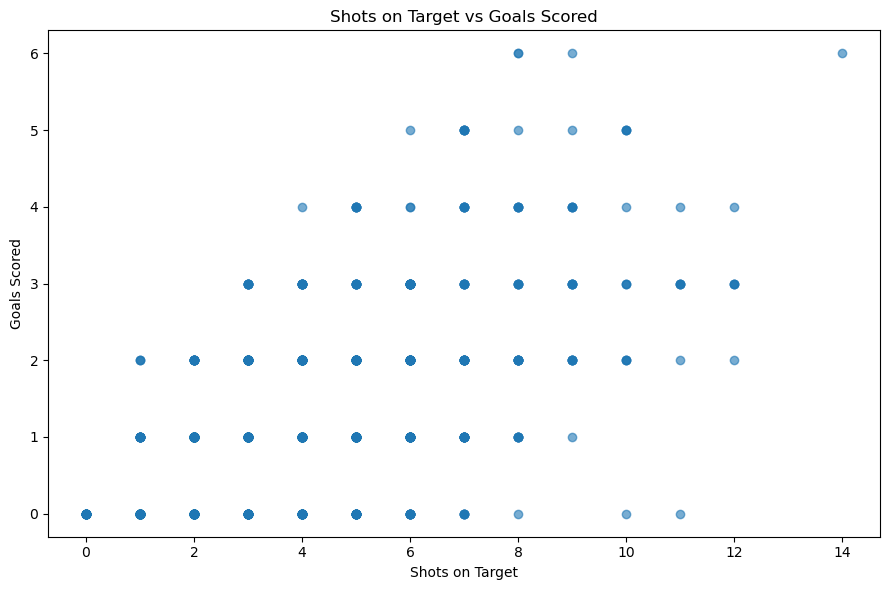

In [33]:
plt.figure(figsize=(9,6))

plt.scatter(team_match_stats["shots_on_target"], team_match_stats["goals"], alpha=0.6)

plt.title("Shots on Target vs Goals Scored")
plt.xlabel("Shots on Target")
plt.ylabel("Goals Scored")
plt.tight_layout()
plt.show()

In [34]:
correlation = team_match_stats[["shots_on_target", "goals"]].corr().iloc[0, 1]

print("Correation:", round(correlation, 3))

Correation: 0.58


### Offensive vs Deffensive performance

In [39]:
# Home matches: goals scored and conceded
home_performance = pd.DataFrame({
    "team": df["home_team_name"],
    "goals_scored": df["home_team_goal_count"],
    "goals_conceded": df["away_team_goal_count"]})

# Away matches: goals scoresd and conceded
away_performance = pd.DataFrame({
    "team": df["away_team_name"],
    "goals_scored": df["away_team_goal_count"],
    "goals_conceded": df["home_team_goal_count"]})

# Combine home and away team's averages
all_performance = pd.concat([home_performance, away_performance], ignore_index=True)

#Calculate each team's averages
team_performance = all_performance.groupby("team")[["goals_scored", "goals_conceded"]].mean()

team_performance.round(2).head()



,goals_scored,goals_conceded
team,,
AFC Bournemouth,1.47,1.84
Arsenal,1.92,1.34
Brighton & Hove Albion,0.92,1.58
Burnley,1.18,1.79
Cardiff City,0.89,1.82


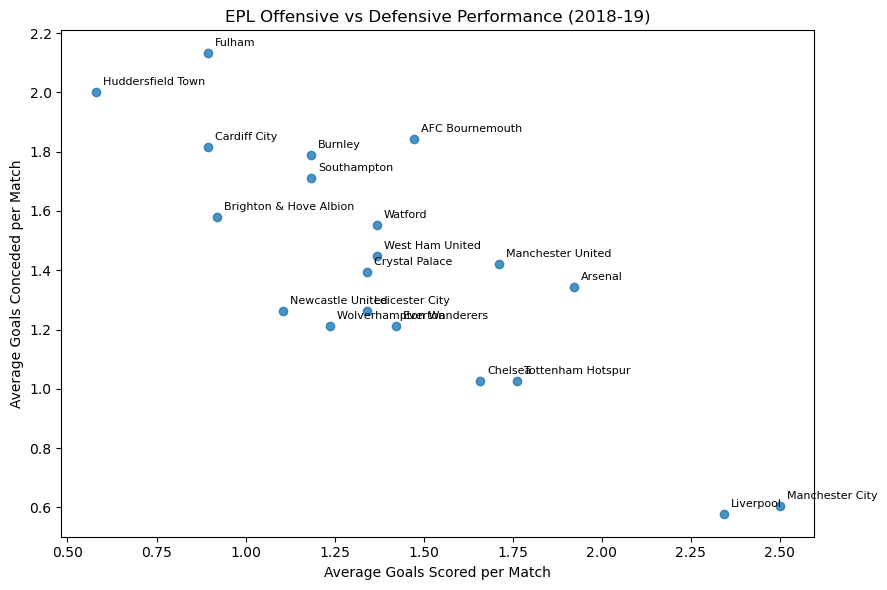

In [46]:
plt.figure(figsize=(9, 6))

plt.scatter(team_performance["goals_scored"],
            team_performance["goals_conceded"],
            alpha = 0.8)

#Label each point with the team naem
for team, row in team_performance.iterrows():
    plt.annotate(team, (row["goals_scored"], row["goals_conceded"]),
                 xytext=(5, 5),
                 textcoords="offset points",
                 fontsize = 8)

plt.title("EPL Offensive vs Defensive Performance (2018-19)")
plt.xlabel("Average Goals Scored per Match")
plt.ylabel("Average Goals Conceded per Match")
plt.tight_layout()
plt.show()